In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
DATA_PATH = Path("../data/raw/employee_attrition.csv")
df = pd.read_csv(DATA_PATH)

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [4]:
print("Dataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe().T)
print("\nCategorical Feature Summary:")
display(df.describe(include="object").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Job

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0



Categorical Feature Summary:


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [5]:
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("\nConstant Columns:")
constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]
print(constant_columns)
print("\nTarget Distribution:")
display(df["Attrition"].value_counts())

print("\nTarget Distribution (%):")
display(
    df["Attrition"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Missing Values: 0
Duplicate Rows: 0

Constant Columns:
['EmployeeCount', 'Over18', 'StandardHours']

Target Distribution:


Attrition
No     1233
Yes     237
Name: count, dtype: int64


Target Distribution (%):


Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

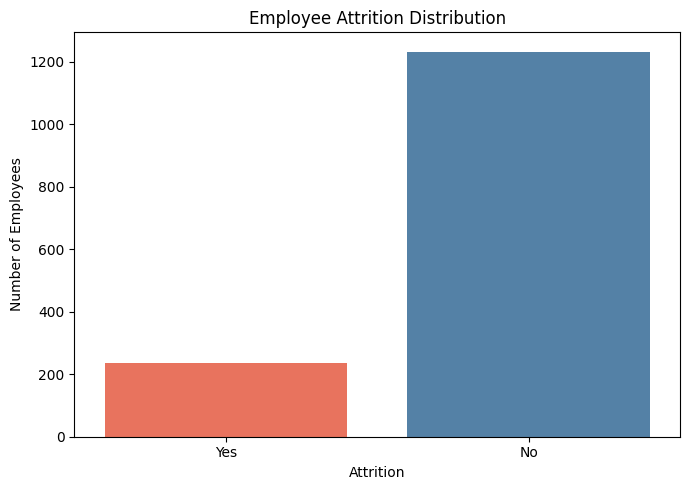

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Attrition",
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "tomato"},
    legend=False
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


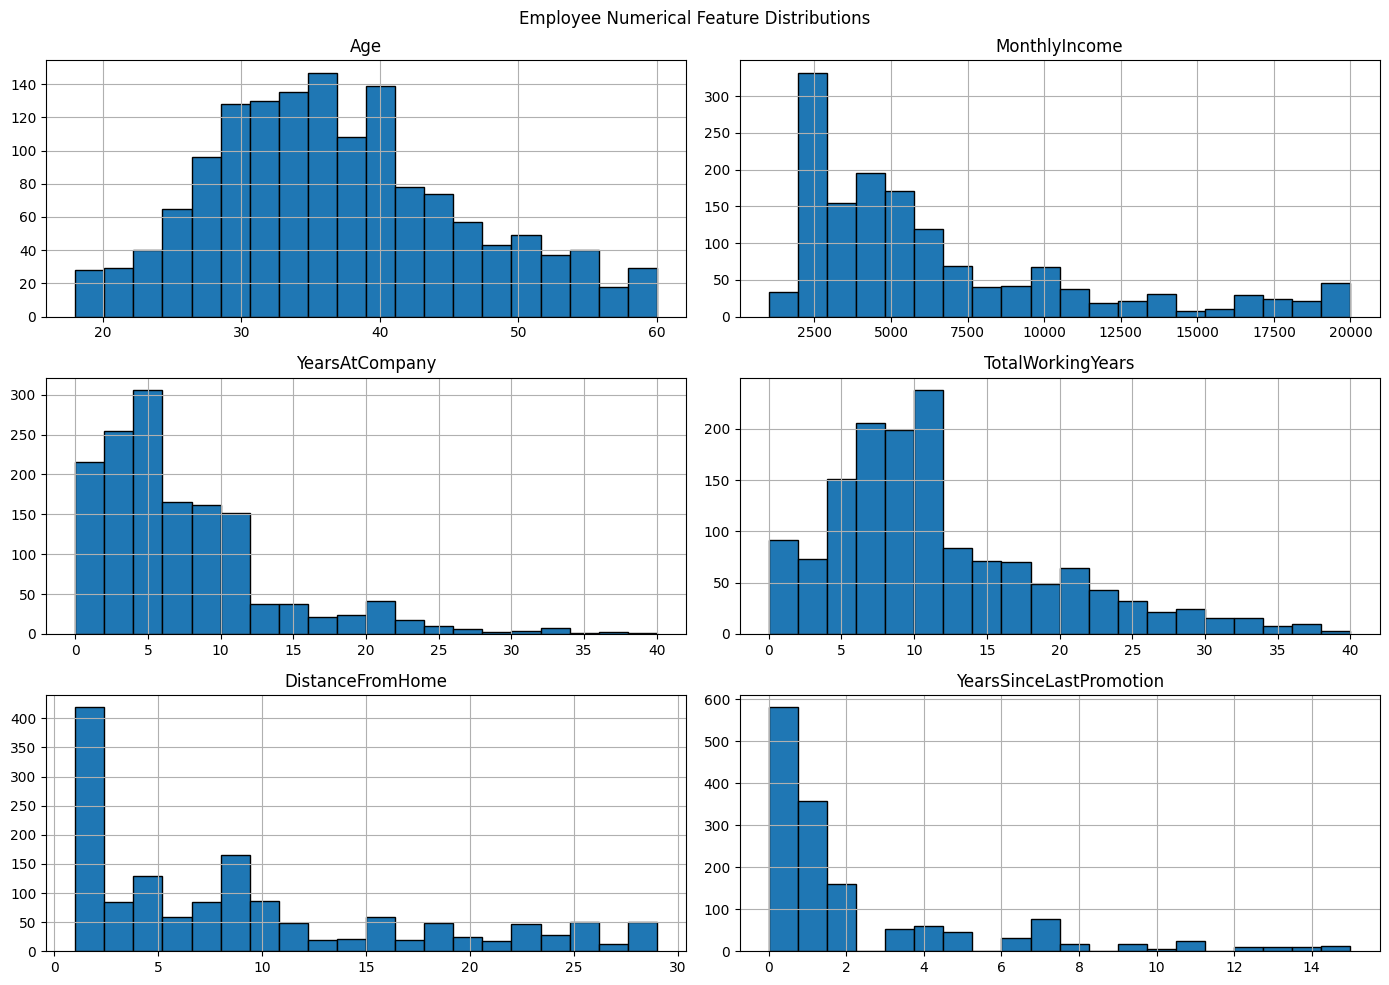

In [7]:
numerical_features = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "TotalWorkingYears",
    "DistanceFromHome",
    "YearsSinceLastPromotion"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Employee Numerical Feature Distributions")
plt.tight_layout()
plt.show()

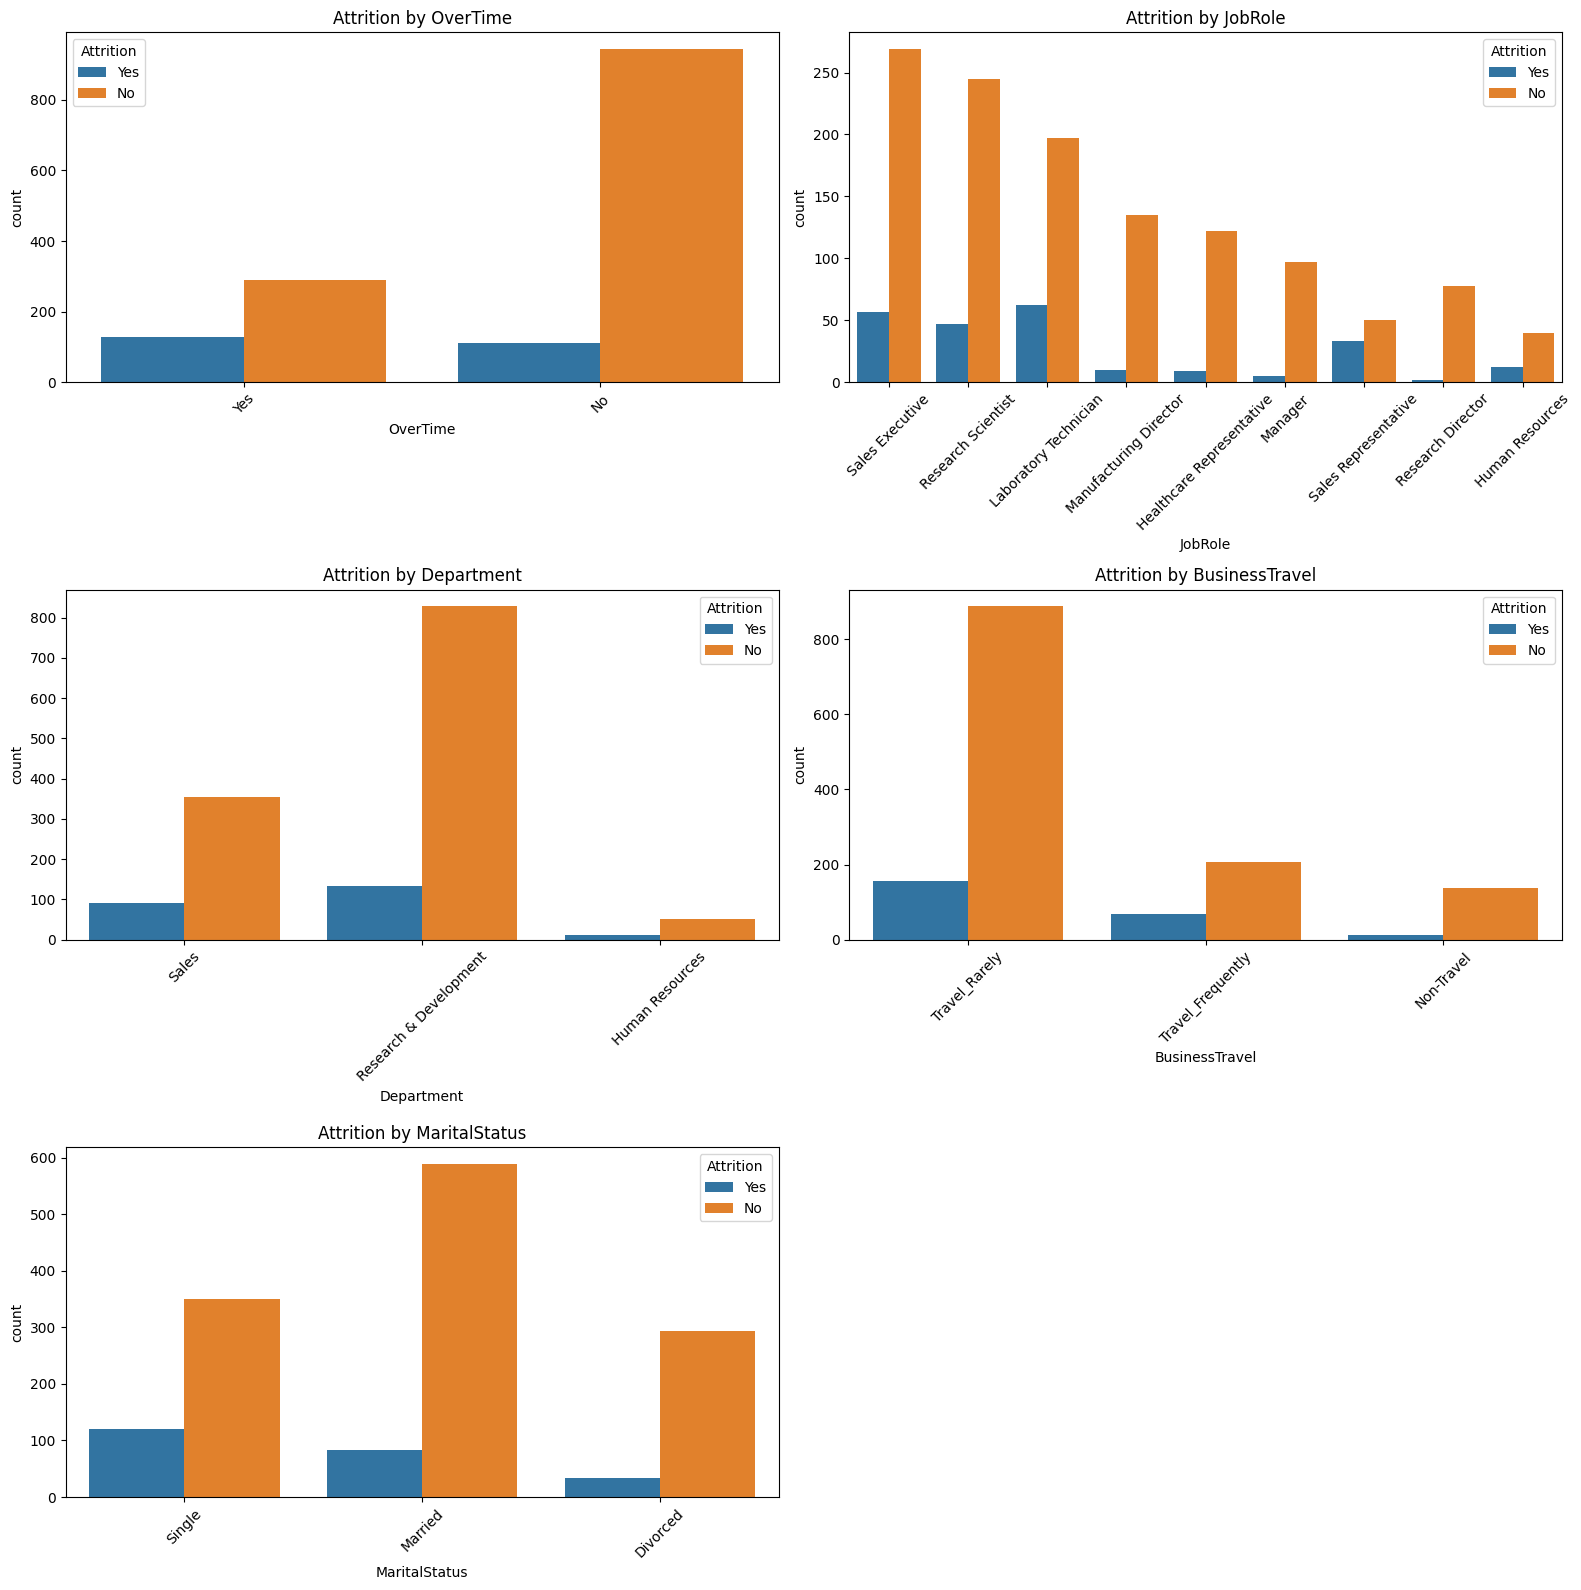

In [8]:
categorical_features = [
    "OverTime",
    "JobRole",
    "Department",
    "BusinessTravel",
    "MaritalStatus"
]

fig, axes = plt.subplots(3, 2, figsize=(16, 16))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    sns.countplot(
        data=df,
        x=feature,
        hue="Attrition",
        ax=axes[i]
    )

    axes[i].set_title(f"Attrition by {feature}")
    axes[i].tick_params(axis="x", rotation=45)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

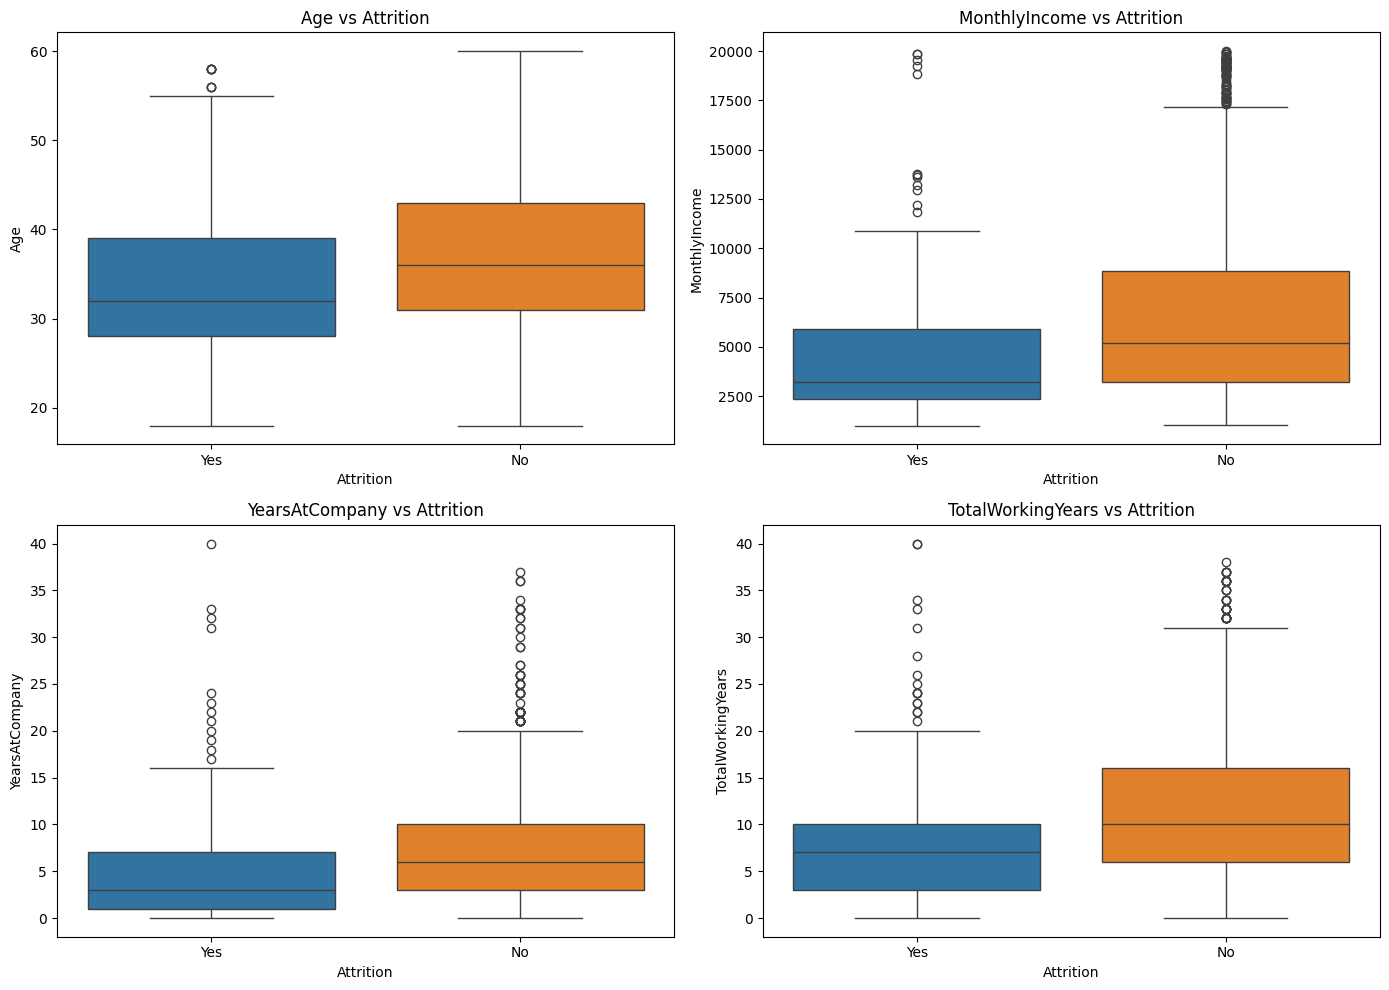

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "TotalWorkingYears"
]

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(
        data=df,
        x="Attrition",
        y=feature,
        hue="Attrition",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{feature} vs Attrition")

plt.tight_layout()
plt.show()